In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from numba import jit

# Linear Burden

In [12]:
def ssa_v(x0,y0,y_div):
    x=[x0]               #molecule count 
    t_x=[0]              #reaction time of fully-observed trajectory
    i=0
    y=y0
    while y<y_div:
        a=q*y
        epsilon=np.random.uniform(0,1,1)
        tau=(np.log(1/epsilon))/a
        x=np.append(x,[x[i]+1])
        beta=beta0*(1-x[i]/m_hat)
        t_x=np.append(t_x,[t_x[i]+tau])
        y=y0*np.exp(beta*(t_x[i+1]-t_x[i]))  #volume at replication
        if y>=y_div:
            x[i+1]=x[i]
            t_x[i+1]=t_x[i]+np.log(y_div/y0)/beta
            y=y_div   #volume at replication
        y0=y
        i+=1
    print(x,y)
    return x,t_x,y

def single_v(x0,gen,y0,y_div):
    x=[x0]
    t=np.array([0])
    for i in range(gen):
        if x0>0:
            xx,tt,yy=ssa_v(x0,y0,y_div)
            x=np.append(x,xx)
            t=np.append(t,t[-1]+tt)
            y0=yy/2
            x0=np.random.binomial(xx[-1],0.5)
            print('############# divide ################')
        else:
            x=np.append(x,[0])
            t=np.append(t,t[-1]+1)
            
    return x,t

def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        plt.plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            plt.vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            plt.vlines(t[i+1],x[i],x[i+1],color='k')
    return None

[ 6  7  8  9 10 11 11] 20
############# divide ################
[ 5  6  7  8  9 10 10] 20
############# divide ################
[5 6 7 8 8] 20
############# divide ################
[4 5 5] 20
############# divide ################
[2 3 4 5 6 7 8 8] 20
############# divide ################
[ 6  7  8  9 10 11 12 13 14 15 15] 20
############# divide ################
[ 6  7  8  9 10 11 12 13 13] 20
############# divide ################
[ 4  5  6  7  8  9 10 11 12 13 13] 20
############# divide ################
[ 7  8  9 10 11 12 13 13] 20
############# divide ################
[ 8  9 10 11 12 12] 20
############# divide ################
[ 8  9 10 11 12 13 14 14] 20
############# divide ################
[ 7  8  9 10 11 12 13 14 15 16 16] 20
############# divide ################
[10 11 12 13 14 15 16 16] 20
############# divide ################
[ 9 10 11 12 13 14 15 16 17 18 18] 20
############# divide ################
[ 7  8  9 10 11 12 13 14 14] 20
############# divide ################
[ 7  

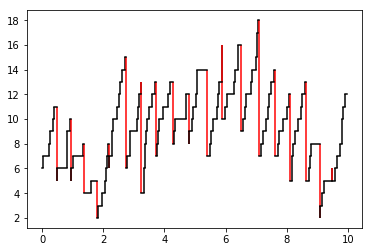

In [13]:
q=1
beta0=2
m_hat=30
x0=6
y_div=20
y0=y_div/2
gen=20
x,t=single_v(x0,gen,y0,y_div)
plot_stairs(x,t)


# Hyperbolic CNC with Hyperbolic burden

In [2]:
def ssa_hyperbolic(x0,y0,y_div):
    x=[x0]               #plasmid count count 
    t_x=[0]              #reaction time of fully-observed trajectory
    i=0
    y=y0
    while y<y_div:
        a=k_tr*x[i]/(1+x[i]/(y*K))
        epsilon=np.random.uniform(0,1,1)
        tau=(np.log(1/epsilon))/a
        x=np.append(x,[x[i]+1])
        beta=b+beta0/(1+x[i]*nu)
        t_x=np.append(t_x,[t_x[i]+tau])
        y=y0*np.exp(beta*(t_x[i+1]-t_x[i]))   #volume at replication
        if y>=y_div:
            x[i+1]=x[i]
            t_x[i+1]=t_x[i]+np.log(y_div/y0)/beta
            y=y_div   #volume at replication
        y0=y
        i+=1
    print(x,y)
    return x,t_x,y



def single_hyperbolic(x0,gen,y0,y_div):
    x=[x0]
    t=np.array([0])
    div_time=np.zeros(gen)
    for i in range(gen):
        if x0>0:
            xx,tt,yy=ssa_hyperbolic(x0,y0,y_div)
            x=np.append(x,xx)
            t=np.append(t,t[-1]+tt)
            y0=yy/2
            x0=np.random.binomial(xx[-1],0.5)
            div_time[i]=t[-1]
            #print(x0)
            print('############# divide ################')
        else:
            x=np.append(x,[0])
            t=np.append(t,t[-1]+1)
            
    return x,t,div_time

def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        plt.plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            plt.vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            plt.vlines(t[i+1],x[i],x[i+1],color='k')
    plt.ylim([0,max(x)+1])
    plt.xlabel('time')
    plt.ylabel('Plasmid copy number')
    return None

[ 6  7  8  9 10 10] 1
############# divide ################
[6 7 8 9 9] 1
############# divide ################
[2 3 3] 1
############# divide ################
[2 3 4 4] 1
############# divide ################
[1 2 3 3] 1
############# divide ################
[1 2 3 3] 1
############# divide ################
[1 2 3 4 4] 1
############# divide ################
[4 5 6 7 7] 1
############# divide ################
[ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 17] 1
############# divide ################
[ 4  5  6  7  8  9 10 11 12 12] 1
############# divide ################


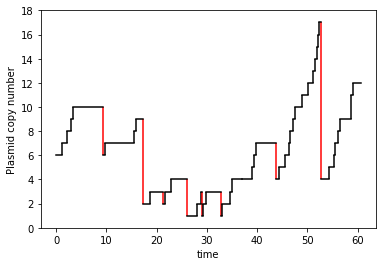

In [26]:
k_tr=1
K=1
beta0=0.4
x0=6
y_div=1
y0=y_div/2
nu=0.5
b=0
gen=10
x,t,div_time=single_hyperbolic(x0,gen,y0,y_div)
plot_stairs(x,t)

Text(0, 0.5, 'Inter-division time')

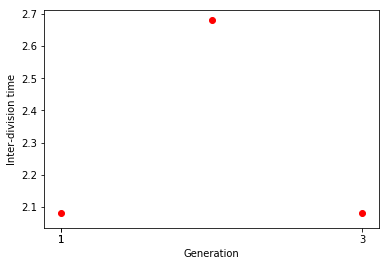

In [8]:
f=plt.figure()
times=np.append([0],div_time)
for i in range(len(times)-1):
    inter=times[i+1]-times[i]
    if times[i+1]-times[i]<0:
        inter=0
    plt.scatter([i+1],[inter],color='red')
plt.xticks([1,int(gen/2),gen])
plt.xlabel('Generation')
plt.ylabel('Inter-division time')

In [84]:
times

array([0.        , 0.64675454, 1.28213946, 1.90143902, 2.53273765,
       3.15195356, 3.78351628, 4.39666035, 5.00024587, 5.61527167,
       6.15438614, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        ])

In [ ]:
def ssa_t(x0,T,y0):
    x=[x0]               #molecule count 
    t_x=[0]            #reaction time of fully-observed trajectory
    i=0
    y=y0
    while t_x[i]<T:
        a=(q/y)*x[i]
        epsilon=np.random.uniform(0,1,1)
        tau=(np.log(1/epsilon))/a
        x=np.append(x,[x[i]+1])
        t_x=np.append(t_x,[t_x[i]+tau])
        if t_x[i+1]>T:
            t_x[i+1]=T
            x[i+1]=x[i-1]
            #y=y0*np.exp(beta0*(1-x[i]/m_hat)*(t_x[i]-t_x[i-1]))
        #print((1-x[i]/m_hat))
        y=y0*np.exp(beta0*(1-x[i]/m_hat)*(t_x[i+1]-t_x[i]))   #volume at replication
        y0=y
        #print(y)
        i+=1
    
    return x,t_x,y

def single_t(x0,T,gen,y0):
    x=[x0]
    t=[0]
    for i in range(gen):
        xx,tt,yy=ssa_t(x0,T,y0)
        #print(yy)
        x=np.append(x,xx)
        t=np.append(t,(i+1)*20+tt)
        y0=yy/2
        x0=np.random.binomial(xx[-1],0.5)
        print('############# divide ################')
    return x,t

def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        plt.plot(vec_t,vec_x)
        plt.vlines(t[i+1],x[i],x[i+1])
    return None
        



In [ ]:
q=6
beta0=0.1
m_hat=20
T=20
gen=10
repeat=3
for i in range(repeat):
    x0=10
    y0=10
    x,t=single_t(x0,T,gen,y0)
    plot_stairs(x,t)